In [1]:
# Cell 1 - Setup
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path("~/Data-Science/Praktikum:DS/outlier_detection_pathway_data/p53mutant").expanduser()
DATA_FILE = DATA_DIR / "train_data.data"
GT_FILE = DATA_DIR / "train_gt.csv"
CHUNK_SIZE = 2000  # rows per chunk, tune based on RAM

In [2]:
# Cell 2 - Preview first and last rows of the full file, with "..." in between like the columns
import subprocess
import io
import dataframe_image as dfi

N = 10  # rows to preview at head and tail

# grab the header line separately, needed to parse the tail rows correctly
header_line = subprocess.run(["head", "-n", "1", str(DATA_FILE)], capture_output=True, text=True).stdout

# first N rows: normal read
head_part = pd.read_csv(DATA_FILE, nrows=N, na_values="?")

# last N rows: read efficiently via `tail`, avoiding a full scan of the 3.2GB file
tail_lines = subprocess.run(["tail", "-n", str(N), str(DATA_FILE)], capture_output=True, text=True).stdout
tail_part = pd.read_csv(io.StringIO(header_line + tail_lines), na_values="?")

# combine, use the real row id as the index so the preview reflects true row positions
preview = (
	pd.concat([head_part, tail_part])
	.rename(columns={"Unnamed: 0": "row_id"})
	.set_index("row_id")
)

# slide-friendly version: only first/last N_COLS columns, "..." column in between,
# and a "..." row between head and tail (matches the truncated look)
N_COLS = 5
cols = list(preview.columns)
shown_cols = cols[:N_COLS] + cols[-N_COLS:]

preview_str = preview[shown_cols].astype(str)
preview_str.insert(N_COLS, "...", "...")

sep_row = pd.DataFrame([["..."] * preview_str.shape[1]], columns=preview_str.columns, index=["..."])
preview_export = pd.concat([preview_str.iloc[:N], sep_row, preview_str.iloc[N:]])

dfi.export(preview_export, "data_overview_table.png", table_conversion="matplotlib")
preview_export

,0,1,2,3,4,...,5404,5405,5406,5407,5409
0,-0.1609999984502792,-0.0140000004321336,0.0020000000949949,-0.0359999984502792,-0.032999999821186,...,-0.0109999999403953,0.003000000026077,0.0099999997764825,-0.0070000002160668,NaN
1,-0.1580000072717666,-0.0020000000949949,-0.0120000001043081,-0.025000000372529,-0.0120000001043081,...,-0.0109999999403953,-0.0040000001899898,0.0130000002682209,0.0049999998882412,NaN
2,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN
3,-0.1689999997615814,-0.025000000372529,-0.0099999997764825,-0.0410000011324882,-0.0450000017881393,...,-0.0120000001043081,0.006000000052154,0.0160000007599592,-0.0179999992251396,NaN
4,-0.1829999983310699,-0.0509999990463256,-0.0230000000447034,-0.0769999995827674,-0.0920000001788139,...,-0.0149999996647238,0.0170000009238719,0.0270000007003545,-0.0489999987185001,NaN
6,-0.1500000059604644,0.0160000007599592,-0.0140000004321336,0.0,0.0160000007599592,...,-0.0289999991655349,-0.006000000052154,0.0040000001899898,0.0230000000447034,NaN
7,-0.1580000072717666,0.0020000000949949,-0.0189999993890523,-0.0280000008642673,-0.0080000003799796,...,-0.0089999996125698,-0.0010000000474974,0.0170000009238719,0.0120000001043081,NaN
8,-0.1519999951124191,0.0089999996125698,-0.0149999996647238,-0.0080000003799796,0.0040000001899898,...,-0.0120000001043081,-0.0089999996125698,0.0080000003799796,0.0209999997168779,NaN
9,-0.1720000058412552,-0.0280000008642673,0.003000000026077,-0.0450000017881393,-0.0549999997019767,...,-0.0049999998882412,0.1369999945163726,0.0979999974370002,-0.0149999996647238,NaN
10,-0.164000004529953,-0.0189999993890523,-0.0109999999403953,-0.0370000004768371,-0.0309999994933605,...,-0.0120000001043081,0.0020000000949949,0.0140000004321336,-0.0089999996125698,NaN


In [3]:
# Cell 3 - Inspect structure on a tiny sample first
sample = pd.read_csv(DATA_FILE, nrows=5, na_values="?")
print(sample.shape)
print(sample.columns[:5], sample.columns[-3:])

(5, 5410)
Index(['Unnamed: 0', '0', '1', '2', '3'], dtype='str') Index(['5406', '5407', '5409'], dtype='str')


In [4]:
# Cell 4 - Investigate the mysterious "5409" column
print(sample.columns[-10:].tolist())   # check if "5408" shows up anywhere nearby
print(sample[["5409"]])                # inspect raw values of this column

gt_sample = pd.read_csv(GT_FILE, nrows=5)
print(gt_sample)                       # compare against the real labels in train_gt.csv

['5399', '5400', '5401', '5402', '5403', '5404', '5405', '5406', '5407', '5409']
   5409
0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
   Unnamed: 0      5408
0           0  inactive
1           1  inactive
2           2  inactive
3           3  inactive
4           4  inactive


## Full-file exploration: missing value structure

The 5-row sample suggested that column "5409" might be an empty leftover
column and that "?" encodes missing values. Before any cleaning, we verify
these findings across the full 31,021-row file using chunked reading.

In [5]:
# Cell 5 - Verify column "5409" is empty across the entire file, not just the 5-row sample
non_empty_5409 = 0
total_rows_checked = 0

for chunk in pd.read_csv(DATA_FILE, na_values="?", chunksize=CHUNK_SIZE):
	non_empty_5409 += chunk["5409"].notna().sum()
	total_rows_checked += len(chunk)

print(f"Rows checked: {total_rows_checked}")
print(f"Non-empty values in column '5409': {non_empty_5409}")

Rows checked: 31020
Non-empty values in column '5409': 0


In [6]:
# Cell 6 - Reproduce the missing-value distribution found earlier via awk, now in pandas
missing_counts = []

for chunk in pd.read_csv(DATA_FILE, na_values="?", chunksize=CHUNK_SIZE):
	feature_cols = chunk.columns.drop(["Unnamed: 0", "5409"])
	missing_counts.append(chunk[feature_cols].isna().sum(axis=1))

missing_per_row = pd.concat(missing_counts)
print(missing_per_row.value_counts().sort_index())

0       30759
4826      124
5408      137
Name: count, dtype: int64


In [7]:
# Cell 8 - Verify the hypothesis that rows missing 4826 values are missing
# exactly the 2D feature block (cols "0" to "4825"), not a random scatter
feature_cols = sample.columns.drop(["Unnamed: 0", "5409"])
two_d_cols = feature_cols[:4826]
three_d_cols = feature_cols[4826:]

example_row = None
for chunk in pd.read_csv(DATA_FILE, na_values="?", chunksize=CHUNK_SIZE):
	row_missing = chunk[feature_cols].isna().sum(axis=1)
	candidates = chunk[row_missing == 4826]
	if len(candidates) > 0:
		example_row = candidates.iloc[[0]]
		break

print("Missing in 2D block:", example_row[two_d_cols].isna().sum(axis=1).values[0])
print("Missing in 3D block:", example_row[three_d_cols].isna().sum(axis=1).values[0])

Missing in 2D block: 4826
Missing in 3D block: 0


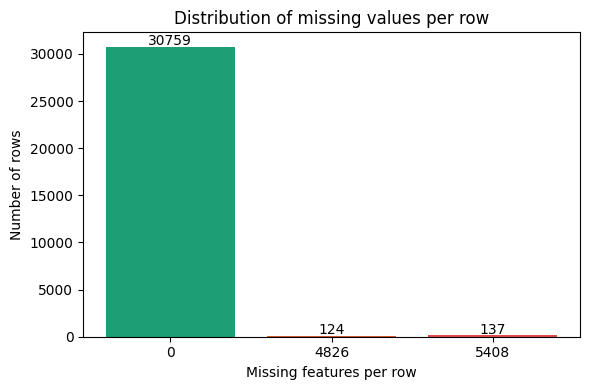

In [8]:
# Cell 9 - Bar chart of the missing-value distribution per row
import matplotlib.pyplot as plt

counts = missing_per_row.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(counts.index.astype(str), counts.values, color=["#1D9E75", "#D85A30", "#E24B4A"])
ax.set_xlabel("Missing features per row")
ax.set_ylabel("Number of rows")
ax.set_title("Distribution of missing values per row")
for i, v in enumerate(counts.values):
	ax.text(i, v + 200, str(v), ha="center")
plt.tight_layout()
plt.savefig(DATA_DIR / "missing_value_distribution.png", dpi=150)
plt.show()

In [9]:
# Cell 10 - Cleaning pipeline: drop fully-empty rows, drop rows missing the 2D block,
# drop duplicate rows, downcast dtype, drop the trailing artifact column.
# No Parquet export here yet -- that comes after label alignment (step 3).
seen_hashes = {}
duplicate_rows = []
cleaned_chunks = []

stats = {
	"rows_read": 0,
	"fully_empty_dropped": 0,
	"missing_2d_dropped": 0,
	"duplicates_dropped": 0,
	"rows_remaining": 0,
}

for chunk in pd.read_csv(DATA_FILE, na_values="?", chunksize=CHUNK_SIZE):
	chunk = chunk.rename(columns={"Unnamed: 0": "id"}).set_index("id")
	if "5409" in chunk.columns:
		chunk = chunk.drop(columns=["5409"])

	stats["rows_read"] += len(chunk)

	# drop rows with no features at all
	n_features = chunk.shape[1]
	row_missing = chunk.isna().sum(axis=1)

	fully_empty_mask = row_missing == n_features
	stats["fully_empty_dropped"] += fully_empty_mask.sum()
	chunk = chunk[~fully_empty_mask]
	row_missing = row_missing[~fully_empty_mask]

	# drop rows missing exactly the 2D feature block
	missing_2d_mask = row_missing == 4826
	stats["missing_2d_dropped"] += missing_2d_mask.sum()
	chunk = chunk[~missing_2d_mask]

	# downcast to float32 to roughly halve memory footprint
	chunk = chunk.astype("float32")

	# hash each remaining row, drop duplicates against everything seen so far
	row_hashes = pd.util.hash_pandas_object(chunk, index=False)
	keep_mask = []
	for row_id, h in zip(chunk.index, row_hashes):
		if h in seen_hashes:
			duplicate_rows.append((row_id, seen_hashes[h]))
			keep_mask.append(False)
		else:
			seen_hashes[h] = row_id
			keep_mask.append(True)

	chunk = chunk[keep_mask]
	stats["duplicates_dropped"] = len(duplicate_rows)

	cleaned_chunks.append(chunk)

df_clean = pd.concat(cleaned_chunks)
stats["rows_remaining"] = len(df_clean)

for k, v in stats.items():
	print(f"{k}: {v}")

print(f"\nMemory usage of df_clean: {df_clean.memory_usage(deep=True).sum() / 1e6:.1f} MB")

rows_read: 31020
fully_empty_dropped: 137
missing_2d_dropped: 124
duplicates_dropped: 5
rows_remaining: 30754

Memory usage of df_clean: 665.5 MB


Labels loaded: 31020
Cleaned feature rows: 30754
Feature rows with no matching label: 0

Label counts:
label
inactive    30693
active         61
Name: count, dtype: int64

Imbalance ratio: 503.2 : 1


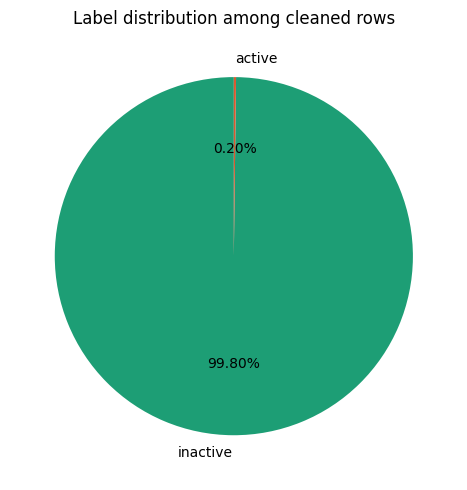

In [10]:
# Cell 11 - Load labels, align them with the cleaned feature rows (verification only,
# NOT used in the exploration/correlation analysis itself per the "don't use target" rule),
# and visualize the resulting label distribution
gt = pd.read_csv(GT_FILE)
gt = gt.rename(columns={"Unnamed: 0": "id", "5408": "label"}).set_index("id")

print(f"Labels loaded: {len(gt)}")
print(f"Cleaned feature rows: {len(df_clean)}")

# check that every remaining feature row has a matching label
missing_labels = df_clean.index.difference(gt.index)
print(f"Feature rows with no matching label: {len(missing_labels)}")

# the gt file still contains labels for rows we dropped (empty / 2D-missing / duplicates) -
# keep only the labels that correspond to rows we actually kept
gt_aligned = gt.loc[df_clean.index]
label_counts = gt_aligned["label"].value_counts()

print(f"\nLabel counts:\n{label_counts}")
print(f"\nImbalance ratio: {label_counts.max() / label_counts.min():.1f} : 1")

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(
	label_counts.values,
	labels=label_counts.index,
	autopct="%1.2f%%",
	colors=["#1D9E75", "#D85A30"],
	startangle=90,
)
ax.set_title("Label distribution among cleaned rows")
plt.tight_layout()
plt.savefig(DATA_DIR / "label_distribution.png", dpi=150)
plt.show()

In [11]:
# Cell 12 - Export the cleaned dataframe to Parquet
OUTPUT_FILE = DATA_DIR / "train_data_clean.parquet"
df_clean.to_parquet(OUTPUT_FILE)

print(f"Saved to: {OUTPUT_FILE}")
print(f"File size: {OUTPUT_FILE.stat().st_size / 1e6:.1f} MB")

Saved to: /home/besher/Data-Science/Praktikum:DS/outlier_detection_pathway_data/p53mutant/train_data_clean.parquet
File size: 281.4 MB


## Note: why file size changes at each stage

The same data goes through three very different size representations:

1. **Raw CSV file (~3.2 GB):** every number is stored as plain text
   (e.g. `0.46799999475479126` is 19 characters = ~19-20 bytes per value,
   including the separating comma).
2. **In-memory DataFrame after cleaning (~665.5 MB):** numbers are stored
   as `float32`, a fixed 4 bytes per value, regardless of how many digits
   the text representation had. This alone explains a ~5x size reduction.
   A small additional reduction comes from dropping 266 invalid/duplicate
   rows (~0.86% of all rows) during cleaning.
3. **Parquet file on disk (~281.4 MB):** on top of the binary float32
   representation, Parquet applies Snappy compression and a columnar
   layout, which compresses repeating patterns within each feature column.
   This gives an additional ~2.4x reduction on top of stage 2.

Text-vs-binary encoding (stage 1 -> 2) accounts for most of the overall
size reduction; compression (stage 2 -> 3) is a smaller, additional gain
on top of that.

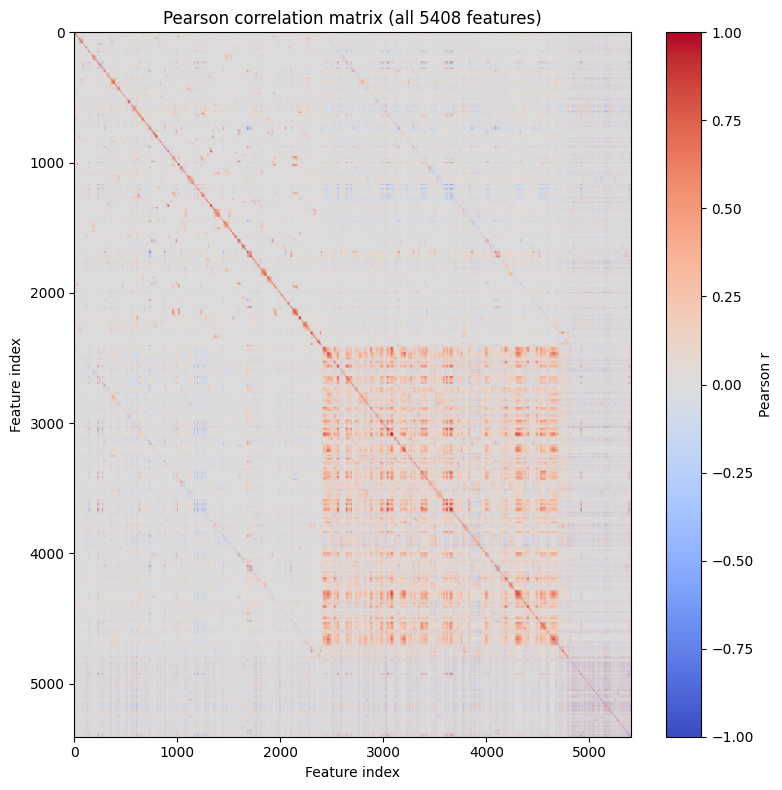

In [12]:
# Cell 13 - Load and plot the precomputed Pearson correlation matrix (computed on the server)
pearson_corr = pd.read_parquet(DATA_DIR / "pearson_corr.parquet")

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(pearson_corr.values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_title("Pearson correlation matrix (all 5408 features)")
ax.set_xlabel("Feature index")
ax.set_ylabel("Feature index")
fig.colorbar(im, ax=ax, label="Pearson r")
plt.tight_layout()
plt.savefig(DATA_DIR / "pearson_correlation_matrix.png", dpi=150)
plt.show()

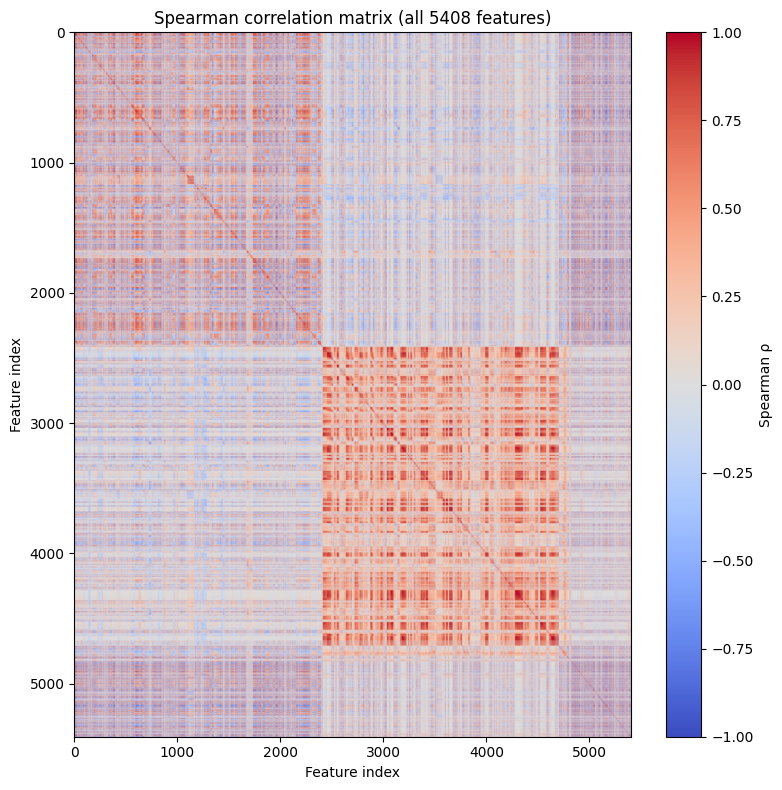

In [13]:
# Cell 14 - Load and plot the precomputed Spearman correlation matrix
spearman_corr = pd.read_parquet(DATA_DIR / "spearman_corr.parquet")

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(spearman_corr.values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_title("Spearman correlation matrix (all 5408 features)")
ax.set_xlabel("Feature index")
ax.set_ylabel("Feature index")
fig.colorbar(im, ax=ax, label="Spearman ρ")
plt.tight_layout()
plt.savefig(DATA_DIR / "spearman_correlation_matrix.png", dpi=150)
plt.show()

## Results: top correlated pairs

**Pearson — most striking pattern:** many of the top pairs involve directly
adjacent column indices (`2405-2406`, `881-882`, `2403-2404`, `1680-1681`,
`1719-1720`, ...). This strongly suggests the features are ordered in a
meaningful spatial/sequential way -- adjacent indices likely describe
neighboring atoms/positions in the protein structure that barely differ.

**Spearman — even a continuous chain shows up:** `3191-3192`, `3192-3193`,
`3193-3194` -- four consecutive features that are nearly identical
(r > 0.998). Again mostly neighbor pairs, plus a few interesting
"long-range" relationships such as `3197-4649` (far apart in index, yet
extremely strongly correlated).

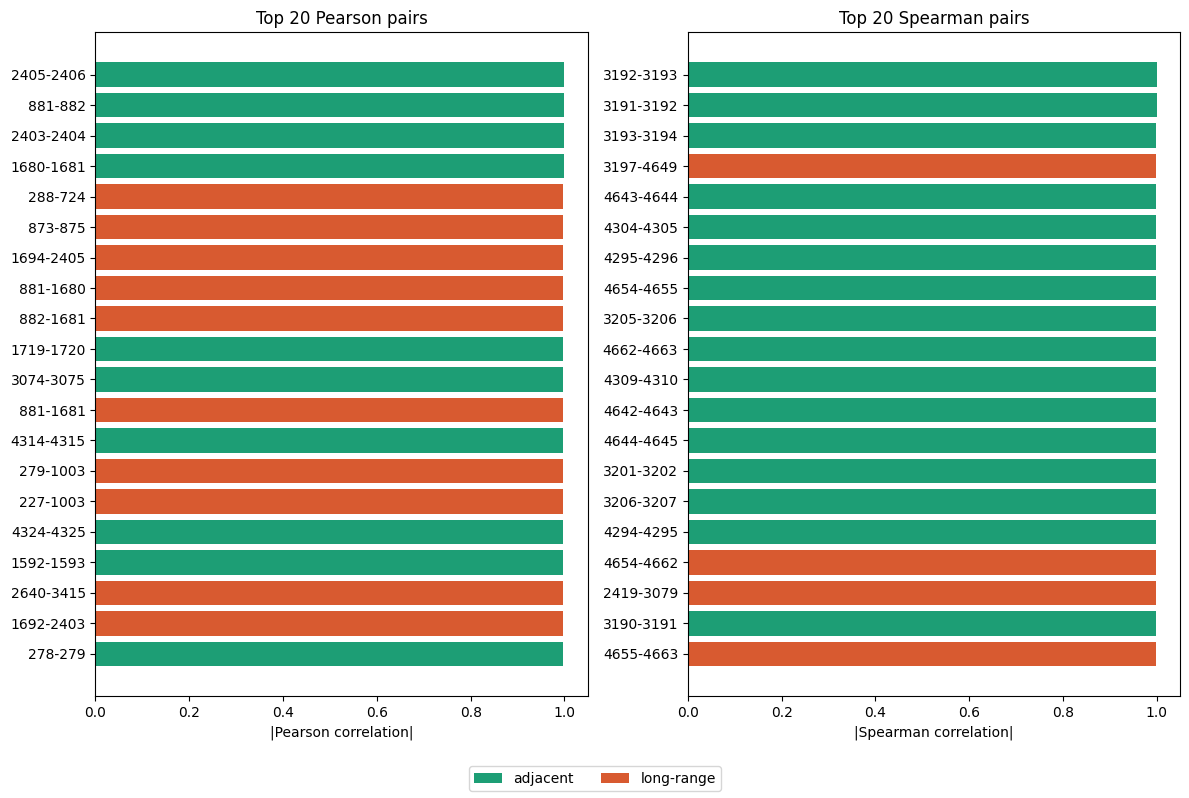

In [14]:
# Cell 15 - Extract top-N strongest Pearson/Spearman pairs and visualize them
# side by side, color-coded by adjacent-index vs. long-range
def top_pairs(corr_matrix, n=20):
	mask = np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
	corr_values = corr_matrix.where(mask).stack()
	top = corr_values.abs().sort_values(ascending=False).head(n)
	return corr_values.loc[top.index]

def prepare_for_plot(top_series):
	df = top_series.rename("correlation").reset_index()
	df.columns = ["feature_a", "feature_b", "correlation"]
	df["gap"] = (df["feature_b"].astype(int) - df["feature_a"].astype(int)).abs()
	df["pair_label"] = df["feature_a"].astype(str) + "-" + df["feature_b"].astype(str)
	df["pair_type"] = df["gap"].apply(lambda g: "adjacent" if g == 1 else "long-range")
	return df.reindex(df["correlation"].abs().sort_values().index)

pearson_top = top_pairs(pearson_corr, 20)
spearman_top = top_pairs(spearman_corr, 20)
candidate_pairs = set(pearson_top.index) | set(spearman_top.index)

color_map = {"adjacent": "#1D9E75", "long-range": "#D85A30"}

fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharex=True)
for ax, top_series, title in zip(axes, [pearson_top, spearman_top], ["Pearson", "Spearman"]):
	df = prepare_for_plot(top_series)
	colors = df["pair_type"].map(color_map)
	ax.barh(df["pair_label"], df["correlation"].abs(), color=colors)
	ax.set_title(f"Top 20 {title} pairs")
	ax.set_xlabel(f"|{title} correlation|")

from matplotlib.patches import Patch
legend_elems = [Patch(facecolor=c, label=l) for l, c in color_map.items()]
fig.legend(handles=legend_elems, loc="lower center", ncol=2)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(DATA_DIR / "top_correlation_pairs.png", dpi=150)
plt.show()

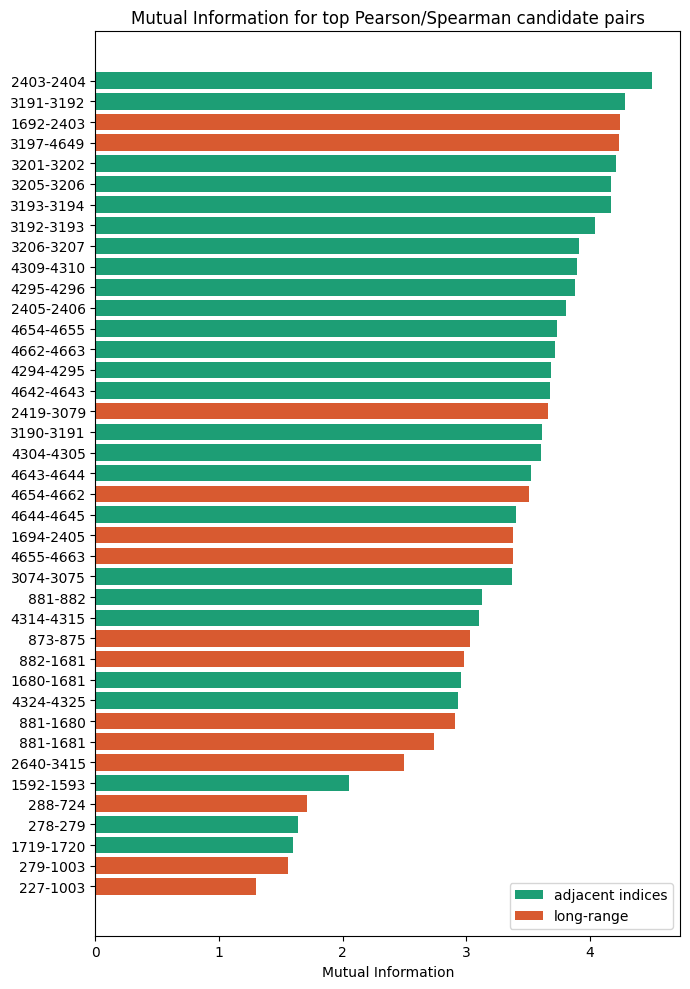

In [15]:
# Cell 16 - Compute Mutual Information on the candidate pairs and visualize it
from sklearn.feature_selection import mutual_info_regression

mi_results = []
for col_a, col_b in candidate_pairs:
	mi = mutual_info_regression(
		df_clean[[col_a]].values, df_clean[col_b].values, random_state=42
	)[0]
	mi_results.append((col_a, col_b, mi))

mi_df = pd.DataFrame(mi_results, columns=["feature_a", "feature_b", "mutual_info"])
mi_df = mi_df.sort_values("mutual_info", ascending=True)
mi_df["gap"] = (mi_df["feature_b"].astype(int) - mi_df["feature_a"].astype(int)).abs()
mi_df["pair_label"] = mi_df["feature_a"].astype(str) + "-" + mi_df["feature_b"].astype(str)
mi_df["pair_type"] = mi_df["gap"].apply(lambda g: "adjacent" if g == 1 else "long-range")

colors = mi_df["pair_type"].map({"adjacent": "#1D9E75", "long-range": "#D85A30"})

fig, ax = plt.subplots(figsize=(7, 10))
ax.barh(mi_df["pair_label"], mi_df["mutual_info"], color=colors)
ax.set_xlabel("Mutual Information")
ax.set_title("Mutual Information for top Pearson/Spearman candidate pairs")

legend_elems = [
	Patch(facecolor="#1D9E75", label="adjacent indices"),
	Patch(facecolor="#D85A30", label="long-range"),
]
ax.legend(handles=legend_elems, loc="lower right")
plt.tight_layout()
plt.savefig(DATA_DIR / "mutual_information_top_pairs.png", dpi=150)
plt.show()

## Note: adjacent vs. long-range pairs

**Adjacent** (green) means the two feature indices differ by exactly 1
(e.g. `2403-2404`). These almost certainly reflect *structural* redundancy:
neighboring indices likely describe physically neighboring atoms/positions
in the protein, so their values barely differ -- not a particularly novel
finding, more a confirmation of how the feature pipeline orders columns.

**Long-range** (orange) means the two indices are far apart in the column
ordering, yet still strongly associated. These are the more interesting
candidates biologically, since there's no obvious structural reason for
them to be related. The standout case here is `3197-4649`: despite a gap
of 1452 indices, its Mutual Information (~4.23) is nearly as high as the
strongest adjacent pairs -- a genuine long-distance dependency worth a
closer look, rather than a pipeline artifact.

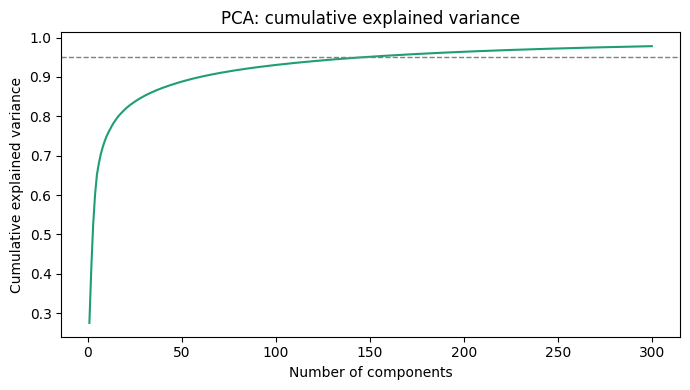

Components needed for 95% variance: 147


In [22]:
# Cell 17 - PCA: cumulative explained variance
# Note: not standardizing features here, since some columns contain large
# outliers that may themselves be the outlier-detection signal we care
# about -- standardizing could mask exactly the structure we're looking for.
# We can revisit this if the result looks dominated by 1-2 extreme features.
from sklearn.decomposition import PCA

n_components = 300
pca = PCA(n_components=n_components, svd_solver="randomized", random_state=42)
pca.fit(df_clean.values)

cumulative = np.cumsum(pca.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, n_components + 1), cumulative, color="#1D9E75")
ax.axhline(0.95, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Number of components")
ax.set_ylabel("Cumulative explained variance")
ax.set_title("PCA: cumulative explained variance")
plt.tight_layout()
plt.savefig(DATA_DIR / "pca_explained_variance.png", dpi=150)
plt.show()

n_for_95 = np.argmax(cumulative >= 0.95) + 1
print(f"Components needed for 95% variance: {n_for_95}")


## Note: what does "147 components for 95% variance" mean?

PCA finds new axes ("principal components") that are combinations of your
5408 original features, ordered by how much of the data's overall spread
(variance) they capture. The first component captures the most, the
second captures the most of what's left, and so on.

**Explained variance ratio** (per component): the fraction of the total
variance in the dataset that this one component captures.

**Cumulative explained variance**: the running total as you add more and
more components. E.g. if components 1-3 individually explain 10%, 7%, and
5%, the cumulative value after 3 components is 22%.

**What "147 components for 95% variance" means here:** instead of needing
all 5408 features to describe how the data varies, just 147 well-chosen
combinations of those features already capture 95% of that variation. In
other words, the effective complexity of the dataset is much lower than
5408 -- roughly a 37x reduction -- which is strong evidence of the
redundancy we already saw in the correlation matrices (many features
moving together). It's not extreme redundancy though (it would take far
fewer components if it were), so there's still meaningful structure beyond
just a handful of dominant patterns.

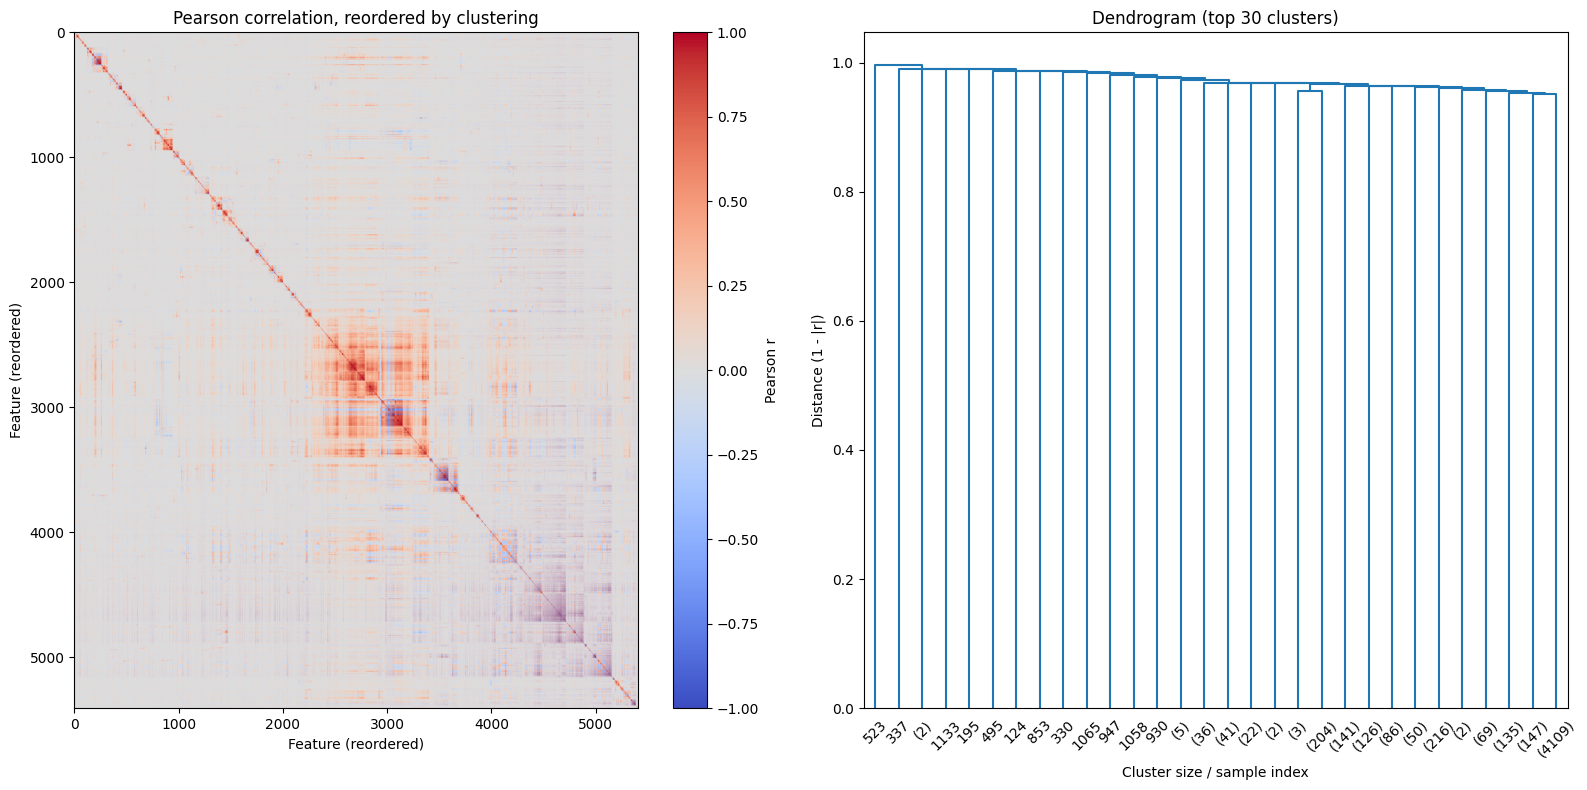

In [17]:
# Cell 18 - Hierarchical clustering on the correlation matrix.
# Distance = 1 - |correlation|: features that move together (regardless of
# sign) are treated as "close", since we care about redundancy, not direction.
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

distance_matrix = 1 - pearson_corr.abs().values
np.fill_diagonal(distance_matrix, 0)  # avoid floating-point noise on the diagonal
condensed = squareform(distance_matrix, checks=False)

linkage_matrix = linkage(condensed, method="average")

# reorder the correlation matrix according to the clustering, for a cleaner heatmap
dendro = dendrogram(linkage_matrix, no_plot=True)
order = dendro["leaves"]
reordered_corr = pearson_corr.values[np.ix_(order, order)]

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

im = axes[0].imshow(reordered_corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
axes[0].set_title("Pearson correlation, reordered by clustering")
axes[0].set_xlabel("Feature (reordered)")
axes[0].set_ylabel("Feature (reordered)")
fig.colorbar(im, ax=axes[0], label="Pearson r")

dendrogram(linkage_matrix, truncate_mode="lastp", p=30, ax=axes[1])
axes[1].set_title("Dendrogram (top 30 clusters)")
axes[1].set_xlabel("Cluster size / sample index")
axes[1].set_ylabel("Distance (1 - |r|)")

plt.tight_layout()
plt.savefig(DATA_DIR / "hierarchical_clustering.png", dpi=150)
plt.show()

## Summary of findings

**Data structure:** 31021 rows (incl. header), 5408 features (V1-V5408 per
the original paper), split into a 2D electrostatic/surface block
(features 0-4825) and a 3D distance-based block (4826-5407). Labels live
separately in `train_gt.csv`.

**Missing values:** not random -- exactly three patterns: 30759 complete
rows, 124 rows missing the entire 2D block (3D values intact), 137 fully
empty rows. Consistent with the paper's two-stage, independently-failing
feature generation pipeline.

**Cleaning:** dropped 137 fully-empty rows, 124 rows missing the 2D block,
and 5 exact duplicate rows -> 30754 clean rows remain. Confirmed zero
remaining NaNs, infinities, constant columns, or duplicate indices.
Downcast to float32 -- verified empirically to lose no real precision
(original values were already float32-precision, just stored as float64).

**Storage:** raw CSV 3.2 GB -> in-RAM float32 665.5 MB (~4.8x, mostly
text-to-binary encoding) -> Parquet on disk 281.4 MB (~2.4x further, via
Snappy compression).

**Label distribution (cleaned rows):** 30693 inactive / 61 active
(~503:1 imbalance), consistent with the paper's reported ratio for this
type of p53 assay.

**Correlation structure:** strong redundancy between *adjacent* feature
indices (near-identical neighbors, e.g. `3191-3193`), plus a few notable
*long-range* pairs (e.g. `3197-4649`) confirmed by Mutual Information, not
just an artifact of outlier-sensitive Pearson. Spearman detects
substantially more structure than Pearson overall, consistent with
non-linear monotonic relationships and outlier sensitivity in Pearson.

**Dimensionality:** PCA shows 147 components capture 95% of the variance
(~37x reduction from 5408) -- meaningful redundancy, but not extreme.

**Clustering:** hierarchical clustering on |correlation| reveals several
compact, tightly-correlated feature groups (both positively and
negatively correlated) sitting within a majority of weakly-correlated
features -- most pairwise correlations are near zero.